<a href="https://colab.research.google.com/github/ojmaldonado/Demograf-a_Soc_Poblaci-n/blob/main/taller_wikipedia_demografia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller: Wikipedia como dato demográfico
**Dinámica Poblacional y Demografía · Universidad del Rosario**

En la última sesión vimos que las plataformas digitales dejan *huellas* que la demografía puede usar para estudiar la población, sobre todo la migración. En este taller vamos a trabajar con una de las fuentes más abiertas: **las vistas de páginas de Wikipedia**.

**Al terminar el taller usted podrá:**
1. Descargar series de vistas diarias o mensuales de cualquier artículo de Wikipedia, en cualquier idioma.
2. Normalizar esas series para poder compararlas entre idiomas.
3. Replicar, en pequeño, el análisis de Coimbra Vieira, Şanlıtürk y Zagheni (2026) sobre refugiados ucranianos y ciudades polacas.
4. Discutir qué puede y qué no puede decirnos esta fuente sobre la población colombiana.

**Qué necesita:** una cuenta de Google para usar [Google Colab](https://colab.research.google.com) (Archivo › Subir cuaderno) o Python con `requests`, `pandas` y `matplotlib`. No hace falta clave de acceso: la API es pública.

> **Recordatorio de la clase.** Wikipedia publica cuántas veces se vio cada página cada día, en cada edición de idioma, desde julio de 2015. **No** dice desde qué país se hizo la consulta. Por eso, en los estudios de migración, el **idioma** se usa como aproximación (*proxy*) del origen.

## Parte 0. Preparación

Ejecute la celda siguiente. Wikimedia pide que cada programa que usa su API se identifique con un nombre y un correo de contacto: **reemplace el correo de ejemplo por el suyo** antes de continuar.

In [1]:
import time
from urllib.parse import quote

import requests
import pandas as pd
import matplotlib.pyplot as plt

# Wikimedia pide identificarse: escriba aquí su correo institucional
USER_AGENT = "TallerDemografiaUR/1.0 (Dinamica Poblacional y Demografia; su_correo@urosario.edu.co)"

sesion = requests.Session()
sesion.headers.update({"User-Agent": USER_AGENT})

API = "https://wikimedia.org/api/rest_v1/metrics/pageviews"

plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

La siguiente celda define cinco funciones que usaremos durante todo el taller. **No necesita modificarlas**, pero lea los comentarios: describen qué pide cada una a la API.

| Función | Qué hace |
|---|---|
| `vistas_articulo()` | Serie de vistas de un artículo en un idioma |
| `vistas_proyecto()` | Total de vistas de toda una edición de Wikipedia (para normalizar) |
| `titulo_en_idioma()` | Traduce el título de un artículo a otra edición de Wikipedia |
| `buscar_articulos()` | Busca artículos por palabras clave |
| `top_por_pais()` / `paises_que_leen()` | Los únicos datos con ubicación: lo más leído desde un país y qué países leen una edición |

In [2]:
def _pedir_json(url, params=None):
    """Hace la consulta, verifica que no haya error y espera un momento para no saturar la API."""
    respuesta = sesion.get(url, params=params, timeout=30)
    respuesta.raise_for_status()
    time.sleep(0.1)
    return respuesta.json()


def _indice_completo(inicio, fin, granularidad):
    """Todas las fechas del periodo: la API omite los días o meses sin vistas."""
    if granularidad == "daily":
        return pd.date_range(inicio, fin, freq="D")
    return pd.date_range(pd.Timestamp(inicio).replace(day=1), fin, freq="MS")


def vistas_articulo(articulo, idioma="es", inicio="20160101", fin="20251231",
                    granularidad="monthly", agente="user"):
    """Vistas de un artículo. granularidad: "daily" o "monthly". agente="user" excluye bots conocidos."""
    titulo = quote(articulo.replace(" ", "_"), safe="")
    url = f"{API}/per-article/{idioma}.wikipedia/all-access/{agente}/{titulo}/{granularidad}/{inicio}/{fin}"
    try:
        datos = _pedir_json(url)
    except requests.HTTPError as error:
        print(f"Sin datos para «{articulo}» en {idioma}.wikipedia ({error.response.status_code})")
        return pd.Series(dtype="float64", name=articulo)
    serie = pd.Series(
        {pd.Timestamp(item["timestamp"][:8]): item["views"] for item in datos["items"]},
        name=articulo, dtype="float64",
    )
    return serie.reindex(_indice_completo(inicio, fin, granularidad), fill_value=0)


def vistas_proyecto(idioma="es", inicio="20160101", fin="20251231",
                    granularidad="monthly", agente="user"):
    """Total de vistas de toda la edición de Wikipedia en ese idioma."""
    url = f"{API}/aggregate/{idioma}.wikipedia/all-access/{agente}/{granularidad}/{inicio}/{fin}"
    datos = _pedir_json(url)
    serie = pd.Series(
        {pd.Timestamp(item["timestamp"][:8]): item["views"] for item in datos["items"]},
        name=f"total_{idioma}", dtype="float64",
    )
    return serie.reindex(_indice_completo(inicio, fin, granularidad))


def titulo_en_idioma(titulo, idioma_origen, idioma_destino):
    """Título del mismo artículo en otra edición (usa los enlaces entre idiomas de Wikipedia)."""
    if idioma_origen == idioma_destino:
        return titulo
    params = {"action": "query", "titles": titulo, "prop": "langlinks", "lllang": idioma_destino,
              "redirects": 1, "format": "json", "formatversion": 2}
    datos = _pedir_json(f"https://{idioma_origen}.wikipedia.org/w/api.php", params)
    enlaces = datos["query"]["pages"][0].get("langlinks", [])
    return enlaces[0]["title"] if enlaces else None


def buscar_articulos(texto, idioma="es", n=5):
    """Títulos de los primeros n artículos que encuentra el buscador de Wikipedia."""
    params = {"action": "query", "list": "search", "srsearch": texto, "srlimit": n,
              "format": "json", "formatversion": 2}
    datos = _pedir_json(f"https://{idioma}.wikipedia.org/w/api.php", params)
    return [resultado["title"] for resultado in datos["query"]["search"]]


def top_por_pais(pais="CO", anio=2024, mes=1, dia=15):
    """Artículos más vistos desde un país en un día (todas las ediciones de Wikipedia)."""
    url = f"{API}/top-per-country/{pais}/all-access/{anio}/{mes:02d}/{dia:02d}"
    tabla = pd.DataFrame(_pedir_json(url)["items"][0]["articles"])
    return tabla.rename(columns={"views_ceil": "vistas_aprox", "views": "vistas_aprox",
                                 "article": "articulo", "project": "proyecto", "rank": "puesto"})


def paises_que_leen(idioma="es", anio=2024, mes=1):
    """Países desde donde se lee una edición de Wikipedia en un mes (vistas en rangos, por privacidad)."""
    url = f"{API}/top-by-country/{idioma}.wikipedia/all-access/{anio}/{mes:02d}"
    tabla = pd.DataFrame(_pedir_json(url)["items"][0]["countries"])
    return tabla.rename(columns={"country": "pais", "views": "vistas_rango",
                                 "views_ceil": "vistas_rango", "rank": "puesto"})


print("Funciones listas.")

Funciones listas.


## Parte 1. Primera consulta: ¿cuánto se lee sobre Bogotá?

Empecemos con una sola serie: las vistas **mensuales** del artículo «Bogotá» en la Wikipedia en español, de 2016 a 2025.

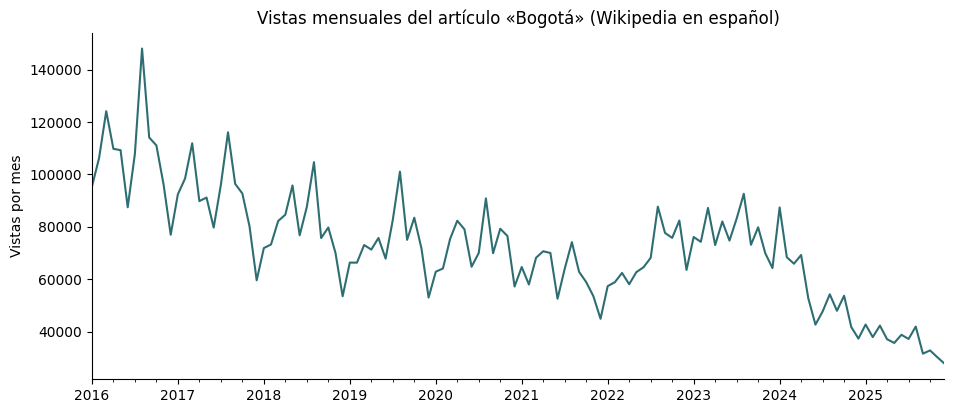

,Bogotá
2025-08-01,41917.0
2025-09-01,31575.0
2025-10-01,32809.0
2025-11-01,30243.0
2025-12-01,27809.0


In [3]:
bogota = vistas_articulo("Bogotá", idioma="es", inicio="20160101", fin="20251231", granularidad="monthly")

bogota.plot(color="#2E6E73")
plt.title("Vistas mensuales del artículo «Bogotá» (Wikipedia en español)")
plt.ylabel("Vistas por mes")
plt.show()

bogota.tail()

**Para discutir**
- ¿Hay picos? Busque qué pasó en esos meses.
- ¿La serie sube o baja en el largo plazo? ¿Eso significa que hay menos interés en Bogotá, o que la gente usa menos Wikipedia (por ejemplo, porque consulta la información en el buscador o en asistentes de inteligencia artificial)?

La segunda pregunta es la razón de la Parte 2.

## Parte 2. Comparar idiomas: por qué hay que normalizar

Si comparamos «Bogotá» en español con «Bogotá» en inglés, el número bruto de vistas no dice mucho: cada edición de Wikipedia tiene un tamaño de público muy distinto, y ese tamaño cambia con el tiempo.

Por eso, igual que en demografía calculamos **tasas** y no solo conteos, aquí dividimos las vistas del artículo entre el **total de vistas de la edición** en el mismo periodo. El resultado lo expresamos en *vistas por millón de vistas del proyecto*.

es: Bogotá
en: Bogotá
pt: Bogotá
fr: Bogota
de: Bogotá


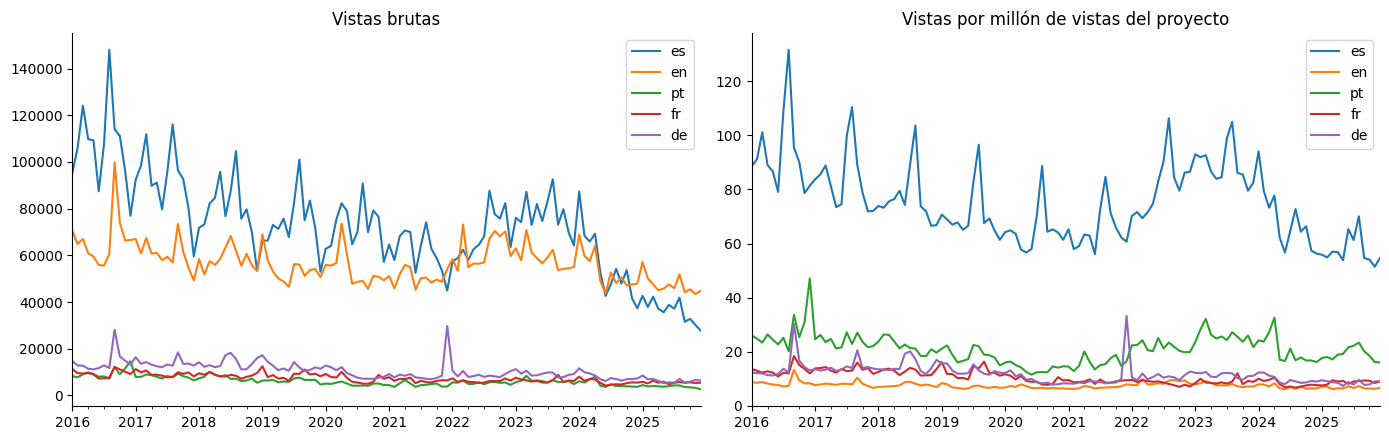

In [4]:
idiomas = ["es", "en", "pt", "fr", "de"]
inicio, fin = "20160101", "20251231"

brutas, normalizadas = {}, {}
for idioma in idiomas:
    titulo = titulo_en_idioma("Bogotá", "es", idioma)
    print(f"{idioma}: {titulo}")
    if titulo is None:
        continue
    serie = vistas_articulo(titulo, idioma, inicio, fin, "monthly")
    total = vistas_proyecto(idioma, inicio, fin, "monthly")
    brutas[idioma] = serie
    normalizadas[idioma] = serie / total * 1_000_000

brutas = pd.DataFrame(brutas)
normalizadas = pd.DataFrame(normalizadas)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
brutas.plot(ax=ejes[0], title="Vistas brutas")
normalizadas.plot(ax=ejes[1], title="Vistas por millón de vistas del proyecto")
plt.tight_layout()
plt.show()

**Para discutir**
- ¿Cambia el orden de los idiomas cuando pasamos de vistas brutas a normalizadas?
- ¿En qué idioma Bogotá ocupa un lugar *relativamente* mayor dentro de su edición? ¿Por qué podría ser?

## Parte 3. Replicar el caso de Ucrania

Coimbra Vieira, Şanlıtürk y Zagheni (2026) mostraron que, tras la invasión rusa del 24 de febrero de 2022, las vistas **en ucraniano** de las páginas de ciudades polacas siguieron a los cruces de refugiados hacia Polonia. Las vistas en polaco o en inglés casi no se movieron.

Vamos a replicar la idea con cinco ciudades y cuatro idiomas. Los pasos son los mismos del artículo:
1. Descargar vistas **diarias** de cada ciudad en cada idioma.
2. Normalizar por el total de la edición.
3. Comparar con una **línea de base**: el promedio antes de la invasión (1 de enero a 23 de febrero). Un índice de 100 significa «igual que antes»; 300, «el triple».

*Esta celda hace unas 25 consultas; puede tardar medio minuto.*

In [5]:
ciudades = ["Warsaw", "Kraków", "Wrocław", "Lublin", "Rzeszów"]   # títulos en la Wikipedia en inglés
idiomas = ["uk", "ru", "pl", "en"]                                 # ucraniano, ruso, polaco, inglés
inicio, fin = "20220101", "20220630"
invasion = pd.Timestamp("2022-02-24")

totales = {idioma: vistas_proyecto(idioma, inicio, fin, "daily") for idioma in idiomas}

filas = []
for ciudad in ciudades:
    for idioma in idiomas:
        titulo = titulo_en_idioma(ciudad, "en", idioma)
        if titulo is None:
            continue
        serie = vistas_articulo(titulo, idioma, inicio, fin, "daily")
        por_millon = serie / totales[idioma] * 1_000_000
        filas.append(pd.DataFrame({"fecha": por_millon.index, "ciudad": ciudad,
                                   "idioma": idioma, "por_millon": por_millon.values}))

panel = pd.concat(filas, ignore_index=True)

# Índice respecto a la línea de base (promedio antes de la invasión = 100)
base = (panel[panel["fecha"] < invasion]
        .groupby(["ciudad", "idioma"])["por_millon"].mean()
        .rename("base"))
panel = panel.join(base, on=["ciudad", "idioma"])
panel["indice"] = panel["por_millon"] / panel["base"] * 100

panel.head()

,fecha,ciudad,idioma,por_millon,base,indice
0,2022-01-01,Warsaw,uk,54.393043,45.36348,119.904917
1,2022-01-02,Warsaw,uk,58.341913,45.36348,128.609870
2,2022-01-03,Warsaw,uk,45.299744,45.36348,99.859500
3,2022-01-04,Warsaw,uk,46.953903,45.36348,103.505956
4,2022-01-05,Warsaw,uk,56.998176,45.36348,125.647715


Primero, el promedio de las cinco ciudades por idioma, suavizado con una media móvil de 7 días:

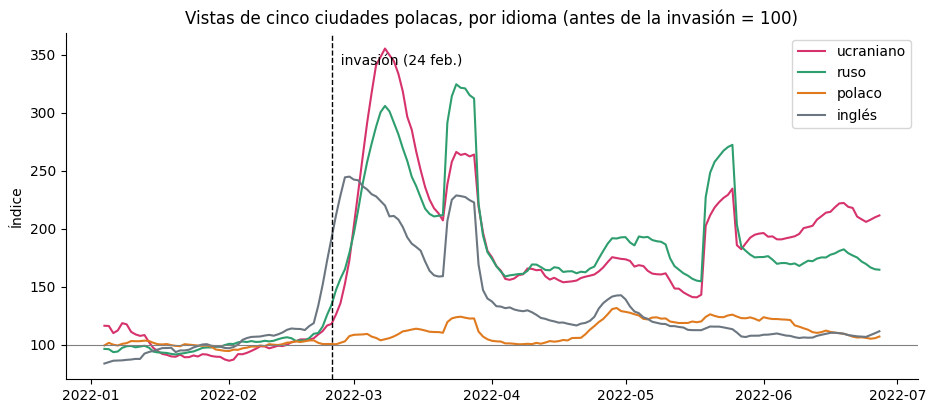

In [6]:
nombres = {"uk": "ucraniano", "ru": "ruso", "pl": "polaco", "en": "inglés"}
colores = {"uk": "#D6336C", "ru": "#2E9E6F", "pl": "#E07A1F", "en": "#6B7680"}

promedio = (panel.groupby(["fecha", "idioma"])["indice"].mean()
            .unstack()
            .rolling(7, center=True).mean())

for idioma in idiomas:
    plt.plot(promedio.index, promedio[idioma], label=nombres[idioma], color=colores[idioma])
plt.axvline(invasion, color="black", linestyle="--", linewidth=1)
plt.axhline(100, color="grey", linewidth=0.8)
plt.text(invasion, plt.ylim()[1] * 0.95, "  invasión (24 feb.)", va="top")
plt.title("Vistas de cinco ciudades polacas, por idioma (antes de la invasión = 100)")
plt.ylabel("Índice")
plt.legend()
plt.show()

Ahora, el **máximo cambio relativo** de cada ciudad en el mes siguiente a la invasión, como en la figura del artículo que vimos en clase:

In [ ]:
primer_mes = panel[(panel["fecha"] >= invasion) & (panel["fecha"] < invasion + pd.Timedelta(days=30))]
cambio_max = (primer_mes.groupby(["ciudad", "idioma"])["indice"].max() - 100).unstack().round(0)
cambio_max = cambio_max.rename(columns=nombres)
cambio_max.style.background_gradient(cmap="OrRd", axis=None).format("{:+.0f} %")

**Para discutir**
- ¿Qué idioma reacciona más? ¿Coincide con lo que encontraron Coimbra Vieira y coautores?
- Rzeszów y Lublin están cerca de la frontera con Ucrania. ¿Se nota en la tabla?
- ¿Por qué el ruso también podría reaccionar? (Pista: ¿qué idiomas hablan las personas que huyeron?)
- Esto es una **asociación temporal**, no una medición de cuántas personas llegaron. ¿Qué dato oficial usaría para validarla? (El artículo usó los cruces de frontera reportados por ACNUR.)

## Parte 4. ¿Y la migración venezolana?

Intentemos lo mismo con un caso cercano. Aquí aparece un problema de fondo: venezolanos y colombianos leen la **misma** Wikipedia en español. El idioma ya no distingue el origen.

Veamos qué países leen la Wikipedia en español. La API solo da **rangos** de vistas y el puesto de cada país, para proteger la privacidad de los lectores.

In [7]:
lectores_es = paises_que_leen("es", anio=2024, mes=1)
lectores_es.head(15)

,pais,vistas_rango,puesto,vistas_rango
0,ES,100000000-999999999,1,255157000
1,MX,100000000-999999999,2,169224000
2,AR,10000000-99999999,3,93443000
3,CO,10000000-99999999,4,71945000
4,CL,10000000-99999999,5,50896000
5,US,10000000-99999999,6,50665000
6,PE,10000000-99999999,7,39007000
7,EC,10000000-99999999,9,26966000
8,DO,10000000-99999999,10,14337000
9,GT,10000000-99999999,11,11539000


**Para discutir:** si Colombia, Venezuela, México y España aparecen todos entre los primeros puestos, ¿podemos atribuir un pico de vistas en español a un grupo de migrantes en particular?

Aun así, la serie puede servir para estudiar el **interés público** en el tema. Busquemos artículos relacionados:

In [8]:
encontrados = buscar_articulos("migración venezolana Colombia", "es", n=8)
for posicion, titulo in enumerate(encontrados):
    print(posicion, titulo)

0 Inmigración venezolana en Colombia
1 Crisis de refugiados venezolana
2 Diáspora venezolana
3 Inmigración venezolana en Perú
4 Crisis entre Colombia y Venezuela de 2015
5 Venezolanos
6 Emigración peatonal venezolana
7 Demografía de Colombia


Elija de la lista los títulos más pertinentes (cambie los números entre corchetes) y grafique su evolución mensual. Las líneas verticales marcan algunos eventos que pueden servir de referencia; agregue otros que conozca.

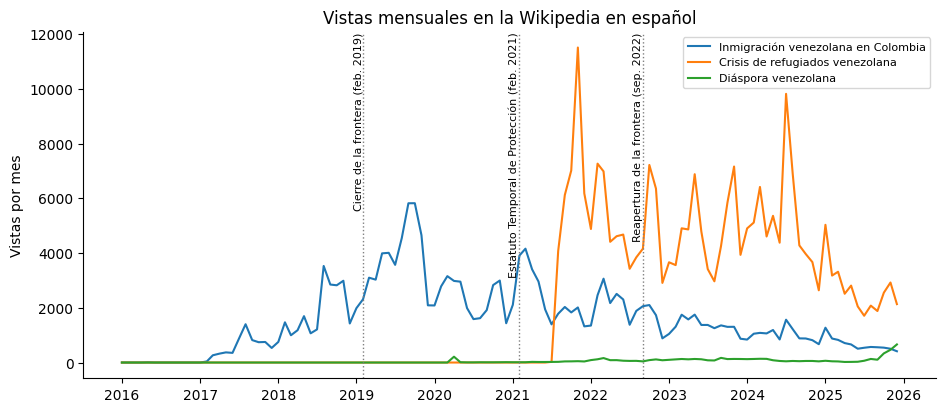

In [9]:
seleccion = [encontrados[i] for i in [0, 1, 2]]   # ajuste según la lista anterior

eventos = {
    "2019-02-01": "Cierre de la frontera (feb. 2019)",
    "2021-02-01": "Estatuto Temporal de Protección (feb. 2021)",
    "2022-09-01": "Reapertura de la frontera (sep. 2022)",
}

for titulo in seleccion:
    serie = vistas_articulo(titulo, "es", "20160101", "20251231", "monthly")
    plt.plot(serie.index, serie, label=titulo)
for fecha, etiqueta in eventos.items():
    plt.axvline(pd.Timestamp(fecha), color="grey", linestyle=":", linewidth=1)
    plt.text(pd.Timestamp(fecha), plt.ylim()[1], etiqueta, rotation=90, va="top", ha="right", fontsize=8)
plt.title("Vistas mensuales en la Wikipedia en español")
plt.ylabel("Vistas por mes")
plt.legend(fontsize=8)
plt.show()

## Parte 5. El único dato con ubicación: lo más leído desde Colombia

Desde 2021 Wikimedia publica, para cada país, los artículos más leídos cada día (en todas las ediciones). Las vistas se redondean hacia arriba para proteger la privacidad. Es lo más cercano a una «población» geográfica que ofrece esta fuente.

In [10]:
top_co = top_por_pais("CO", anio=2024, mes=1, dia=15)

# Quitamos páginas técnicas (portada, búsqueda, etc.)
tecnicas = ("Especial:", "Special:", "Wikipedia:", "Portada", "Main_Page")
top_co = top_co[~top_co["articulo"].str.startswith(tecnicas)]
top_co.head(20)

,articulo,proyecto,vistas_aprox,puesto
1,Vuelo_571_de_la_Fuerza_Aérea_Uruguaya,es.wikipedia,19200,2
2,Cleopatra_I_de_Egipto,es.wikipedia,13700,3
3,La_sociedad_de_la_nieve,es.wikipedia,8700,4
5,Arturo_Vidal,es.wikipedia,6500,6
6,Enilce_López,es.wikipedia,5700,7
8,Bernardo_Arévalo,es.wikipedia,4800,9
9,Blue_Monday_(fecha),es.wikipedia,4400,10
10,Real_Madrid_Club_de_Fútbol,es.wikipedia,3100,11
11,Roberto_Canessa,es.wikipedia,2900,12
12,Premio_The_Best_FIFA,es.wikipedia,2800,13


**Para discutir**
- ¿Qué temas dominan? ¿Cuántos tienen que ver con población (salud, nacimientos, muertes, migración)?
- Cambie la fecha a un día que le interese (por ejemplo, el día de un evento nacional) y compare.
- ¿Por qué Wikimedia publica rangos y no cifras exactas? ¿Qué riesgo habría para personas en situación vulnerable?

## Parte 6. Ejercicios

Elija **uno** y prepare una gráfica con un párrafo de interpretación.

1. **Fecundidad y salud reproductiva.** Use `buscar_articulos()` para encontrar artículos como «Fecundidad», «Anticoncepción» o «Aborto en Colombia». Grafique su evolución mensual. ¿Hay estacionalidad? ¿Se ve algún efecto de la sentencia C-055 de la Corte Constitucional (febrero de 2022)?
2. **Mortalidad.** Compare «Esperanza de vida» y «Pandemia de COVID-19 en Colombia» entre 2019 y 2022, en vistas normalizadas. ¿Qué nos dice el pico sobre la demanda de información en una crisis de mortalidad?
3. **Emigración colombiana.** Grafique en español las vistas de ciudades de destino frecuentes de la emigración colombiana (por ejemplo Madrid, Miami o Santiago de Chile). ¿Puede distinguir el interés de quien migra del interés de cualquier otro lector hispanohablante? Proponga un idioma o una página que sí ayude a distinguirlo.
4. **Diseño propio.** Formule una pregunta demográfica, elija los artículos y el idioma que usaría como *proxy*, y diga con qué dato oficial (DANE, Migración Colombia, ACNUR) validaría su resultado.

## Para cerrar: qué es (y qué no es) una vista de Wikipedia

Antes de sacar conclusiones, recuerde lo que discutimos en clase:

- **Una vista no es una persona.** La misma persona puede ver la página muchas veces; un bot no identificado puede inflar la serie (por eso usamos `agente="user"`, que excluye solo los bots *conocidos*).
- **El idioma no es el origen.** Funciona como *proxy* cuando un idioma está concentrado en un grupo, como el ucraniano en 2022, y falla cuando varios países comparten idioma, como en América Latina.
- **La plataforma cambia.** Cuando cambia cómo se busca información (aplicaciones, buscadores, asistentes de IA), cambian las vistas, aunque la población no cambie. Normalizar ayuda, pero no lo resuelve todo.
- **Calibrar, no reemplazar.** Estas series son más útiles como complemento oportuno de los censos, las encuestas y los registros que como sustituto.

### Referencias
- Coimbra Vieira, C., Şanlıtürk, E. y Zagheni, E. (2026). Forced migration and information seeking behavior on Wikipedia: Insights from the Ukrainian refugee crisis. *Proceedings of the International AAAI Conference on Web and Social Media*, 20(1), 2358–2381.
- Salganik, M. J. (2017). *Bit by Bit: Social Research in the Digital Age*. Princeton University Press.
- Herramienta web para explorar sin código: [pageviews.wmcloud.org](https://pageviews.wmcloud.org/)
- Documentación de la API: [doc.wikimedia.org/generated-data-platform/aqs/analytics-api](https://doc.wikimedia.org/generated-data-platform/aqs/analytics-api/)